# 03 · Inventario de fuentes de arándano y plan de captura propia

Este notebook revisa **qué imágenes de arándano existen, cuáles tenemos realmente, qué aportan y qué falta**, y deja preparado el control de calidad de los datos que capture AGRAR. Funciona aunque falten fuentes (DrBerry sigue bloqueado por `ROBOFLOW_API_KEY`).

- Catálogo (fuente única): `knowledge/datasets/blueberry_image_sources.yaml`
- Auditoría: `reports/blueberry_image_repository_audit.md`
- Las imágenes de terceros se guardan como paneles locales en `reports/figures_local/` (ignorado por Git) y no se incrustan aquí (`SHOW_PANELS = False`).

In [1]:
import sys, json, collections, warnings
from pathlib import Path
import numpy as np, pandas as pd, yaml
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore"); pd.set_option("display.max_colwidth", 70); pd.set_option("display.width", 220)
def _root():
    p = Path.cwd().resolve()
    for c in [p, *p.parents]:
        if (c / "pyproject.toml").exists() and (c / "src" / "berryvision").is_dir():
            return c
    raise FileNotFoundError
VISION = _root(); sys.path.insert(0, str(VISION / "src"))
from berryvision.nbutils import image_stats, save_panel
from berryvision.audit import audit_directory
SHOW_PANELS = False
FIG = VISION / "reports/figures"; PANELS = VISION / "reports/figures_local"
plt.rcParams.update({"figure.dpi": 80, "savefig.dpi": 110})
cat = yaml.safe_load((VISION / "knowledge/datasets/blueberry_image_sources.yaml").read_text(encoding="utf-8"))["sources"]
S = pd.DataFrame(cat)
print(len(S), "fuentes en el catálogo")

33 fuentes en el catálogo


## 1. Catálogo y 2. estado de adquisición

In [2]:
display(pd.crosstab(S.role, S.status))
S[["id", "crop", "target", "n_images", "license", "status", "role"]].astype(str).head(40)

status,ACCESO_PENDIENTE,AUXILIAR,DESCARGADO_Y_AUDITADO,DESCARTADO,LICENCIA_PENDIENTE,NO_APTO_PARA_ENTRENAMIENTO,SOLICITAR_A_AUTORES,SOLO_REFERENCIA_VISUAL,VERIFICADO
role,,,,,,,,,
AUXILIARY_TRAINING,6,3,1,0,0,0,0,0,0
BLOCKED_BY_LICENSE_OR_ACCESS,1,0,0,0,2,0,0,0,0
DOMAIN_GENERALIZATION,1,0,4,0,0,0,1,0,0
ENVIRONMENTAL_RISK_REFERENCE,0,0,0,0,0,0,0,0,1
NOT_RELEVANT_TO_CURRENT_TASK,0,1,0,3,0,2,0,1,0
PRIMARY_TRAINING,2,0,0,0,0,0,0,0,0
VISUAL_REFERENCE_ONLY,0,0,0,0,0,0,0,4,0


,id,crop,target,n_images,license,status,role
0,drberry_original_v1,arándano,"['alternaria', 'oidio', 'heliothis', 'sana']",410,CC BY 4.0 (Roboflow),ACCESO_PENDIENTE,PRIMARY_TRAINING
1,drberry_pry20220204,arándano,"['alternaria', 'oidio', 'heliothis', 'hoja']",633,CC BY 4.0 (Roboflow),ACCESO_PENDIENTE,PRIMARY_TRAINING
2,drberry_codelabs_leaf_detection,arándano,"['alternaria', 'oidio', 'heliothis', 'hoja']",633 base; versión 1 = 1647 (aumentada),CC BY 4.0 (Roboflow),ACCESO_PENDIENTE,AUXILIARY_TRAINING
3,drberry_gen3_20,arándano,"['alternaria', 'oidio', 'heliothis', 'sana']",585,CC BY 4.0,ACCESO_PENDIENTE,AUXILIARY_TRAINING
4,drberry_gen3,arándano,"['alternaria', 'oidio', 'heliothis', 'sana']",2671,CC BY 4.0,ACCESO_PENDIENTE,AUXILIARY_TRAINING
5,mummy_berry_qu2024,arándano lowbush (silvestre),['mummy_berry (Monilinia vaccinii-corymbosi)'],927 originales (artículo); ~1.100-1.230 tras aumentación por tarea,"artículo CC BY; DATOS no publicados (""available by the authors, wi...",SOLICITAR_A_AUTORES,DOMAIN_GENERALIZATION
6,uba_herbario_botrytis_arandano,arándano,['botrytis'],28 (27 de galería + 1 figura); la mayoría microscópicas (conidios/...,sin licencia declarada; '© Facultad de Agronomía - UBA'; página co...,SOLO_REFERENCIA_VISUAL,VISUAL_REFERENCE_ONLY
7,inia_uruguay_poscosecha_2014,arándano,"['botrytis', 'alternaria', 'otros patógenos de poscosecha']",? (guía en PDF),no verificada,SOLO_REFERENCIA_VISUAL,VISUAL_REFERENCE_ONLY
8,inia_chile_boletin_48_cap7,arándano,"['botrytis', 'otras']",?,no verificada,SOLO_REFERENCIA_VISUAL,VISUAL_REFERENCE_ONLY
9,foods2023_hsi_anomaly,"['fresa', 'arándano']","anomalías (golpeado, infectado, daño por frío, arrugado) — sin atr...",?,artículo CC BY (PMC10378827); datos no verificados,NO_APTO_PARA_ENTRENAMIENTO,NOT_RELEVANT_TO_CURRENT_TASK


In [3]:
local = {}
for d in sorted((VISION / "data/external").iterdir()):
    acq = d / "ACQUISITION.json"
    if acq.exists():
        a = json.loads(acq.read_text(encoding="utf-8"))
        local[d.name] = {"adquirido": a.get("acquired_at"), "licencia": a.get("license"),
                         "verificación": "MD5 publicado" if "expected" in json.dumps(a) else "sha256 local",
                         "archivos": a.get("n_files_extracted", a.get("n_downloaded"))}
pd.DataFrame(local).T

,adquirido,licencia,verificación,archivos
blueberry_dcm,2026-10-24T03:06:39+00:00,CC BY-NC 4.0 (no comercial),sha256 local,560
blueberry_yolo_zhang,2026-10-24T03:12:10+00:00,CC BY 4.0,sha256 local,935
plantdoc_blueberry,2026-10-23T23:21:28+00:00,CC BY 4.0 (LICENSE.txt del repositorio); imágenes recopiladas de i...,sha256 local,117
plantvillage_blueberry_healthy,2026-10-23T23:18:30+00:00,CC BY-SA 3.0 (ficha de Hugging Face mohanty/PlantVillage; sin LICE...,sha256 local,1502
strawberry_hybrid,2026-10-24T00:22:32+00:00,CC BY-NC 4.0 (no comercial). Bases de Afzaal 2021 y Pérez-Borrero ...,sha256 local,10207


**Solo estas fuentes existen en disco.** Las demás están identificadas pero pendientes (API key, solicitud a autores, licencia o publicación). No se cuentan imágenes que no se hayan descargado y auditado.

## 3. Distribución por clases y órganos (fuentes descargadas de arándano)

In [4]:
SRC = {"blueberry_dcm": "data/external/blueberry_dcm", "blueberry_yolo_zhang": "data/external/blueberry_yolo_zhang",
       "plantdoc_blueberry": "data/external/plantdoc_blueberry", "plantvillage_blueberry_healthy": "data/external/plantvillage_blueberry_healthy"}
REP = {}
for k, p in SRC.items():
    j = VISION / "reports/audits" / f"{k}.json"
    if j.exists():
        REP[k] = json.loads(j.read_text(encoding="utf-8"))
    elif (VISION / p).exists():
        r = audit_directory(VISION / p); r.pop("_records", None); r.pop("_boxes", None); REP[k] = r
rows = []
for k, r in REP.items():
    anns = r.get("annotations") or [{}]
    a = max(anns, key=lambda x: x.get("n_instances", 0)) if anns[0] else {}
    rows.append({"fuente": k, "imágenes": r["n_images"], "ilegibles": len(r["unreadable"]), "formato": a.get("format", "etiqueta de carpeta"),
                 "instancias": a.get("n_instances", r["n_images"]), "clases": a.get("class_counts", "-"),
                 "órgano anotado": {"blueberry_dcm": "fruto", "blueberry_yolo_zhang": "fruto", "plantdoc_blueberry": "hoja", "plantvillage_blueberry_healthy": "hoja (imagen)"}[k],
                 "¿etiqueta fitosanitaria?": {"plantdoc_blueberry": "no ('Blueberry leaf' sin diagnóstico)", "plantvillage_blueberry_healthy": "sana de laboratorio"}.get(k, "NO (madurez de fruto)")})
pd.DataFrame(rows).set_index("fuente")

,imágenes,ilegibles,formato,instancias,clases,órgano anotado,¿etiqueta fitosanitaria?
fuente,,,,,,,
blueberry_dcm,140,0,yolo,17955,"{'id_0': 10981, 'id_3': 6974}",fruto,NO (madurez de fruto)
blueberry_yolo_zhang,466,0,yolo,27935,"{'blueberry_green': 8000, 'blueberry_ripe': 19935}",fruto,NO (madurez de fruto)
plantdoc_blueberry,117,0,csv_boxes,849,{'Blueberry leaf': 849},hoja,no ('Blueberry leaf' sin diagnóstico)
plantvillage_blueberry_healthy,1502,0,etiqueta de carpeta,1502,-,hoja (imagen),sana de laboratorio


**Lectura.** Ninguna de las fuentes descargadas de arándano tiene etiquetas de enfermedad. BlueberryDCM y Blueberry YOLO anotan **frutos** (madurez y oclusión); PlantDoc anota **hojas** sin diagnóstico; PlantVillage es una sola clase de laboratorio.

## 4. Comparación visual entre fuentes (dominio)

,brightness,saturation,sharpness,mean_g
fuente,,,,
blueberry_dcm,120.5,81.1,4575.7,116.0
blueberry_yolo_zhang,120.3,66.1,4200.9,118.0
plantdoc_blueberry,145.3,97.3,2337.3,134.9
plantvillage_blueberry_healthy,150.4,52.0,5366.9,141.8


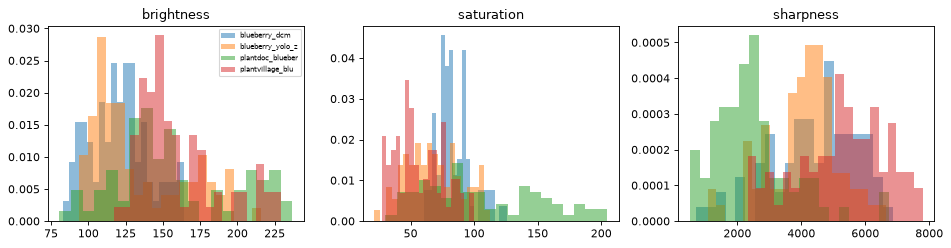

In [5]:
st = []
for k, p in SRC.items():
    files = sorted(f for f in (VISION / p).rglob("*") if f.suffix.lower() in (".jpg", ".jpeg", ".png"))
    rng = np.random.default_rng(0)
    for f in rng.choice(files, size=min(80, len(files)), replace=False):
        s = image_stats(f); s["fuente"] = k; st.append(s)
D = pd.DataFrame(st)
display(D.groupby("fuente")[["brightness", "saturation", "sharpness", "mean_g"]].median().round(1))
fig, axs = plt.subplots(1, 3, figsize=(12, 3.2))
for ax, c in zip(axs, ["brightness", "saturation", "sharpness"]):
    for k, g in D.groupby("fuente"): ax.hist(g[c], bins=20, alpha=.5, density=True, label=k[:16])
    ax.set_title(c)
axs[0].legend(fontsize=6); plt.tight_layout(); plt.savefig(FIG / "nb03_blueberry_domain_stats.png"); plt.show()

**Lectura.** Las escenas de campo (BlueberryDCM, Blueberry YOLO) difieren de las de laboratorio (PlantVillage) y de las fotos web (PlantDoc). Para medir **falsas alarmas en escenas reales de arándano**, las de campo son las más parecidas a lo que verá el robot.

## 5. Galería de ejemplos autorizados (paneles locales)

In [6]:
paths = {}
for k, p in SRC.items():
    files = sorted(f for f in (VISION / p).rglob("*") if f.suffix.lower() in (".jpg", ".jpeg", ".png"))
    rng = np.random.default_rng(1); pick = rng.choice(files, size=min(12, len(files)), replace=False)
    paths[k] = save_panel([{"rel_path": f.relative_to(VISION).as_posix(), "title": k[:20]} for f in pick], VISION, PANELS / f"nb03_{k}.jpg", draw_boxes=False)
if SHOW_PANELS:
    from IPython.display import Image as _I, display as _d
    for v in paths.values(): _d(_I(filename=str(v)))
pd.Series({k: str(v.relative_to(VISION)) for k, v in paths.items()}, name="panel local")

blueberry_dcm                                      reports\figures_local\nb03_blueberry_dcm.jpg
blueberry_yolo_zhang                        reports\figures_local\nb03_blueberry_yolo_zhang.jpg
plantdoc_blueberry                            reports\figures_local\nb03_plantdoc_blueberry.jpg
plantvillage_blueberry_healthy    reports\figures_local\nb03_plantvillage_blueberry_healthy.jpg
Name: panel local, dtype: str

## 6. Calidad de anotaciones y 7. tamaño relativo de los objetos

In [7]:
q = []
for k, r in REP.items():
    for a in r.get("annotations", []):
        for c, b in a.get("box_stats", {}).items():
            q.append({"fuente": k, "formato": a["format"], "clase": c, "cajas": b["n_boxes"], "área mediana": b["rel_area_median"], "p90": b["rel_area_p90"]})
Q = pd.DataFrame(q); display(Q)
dcm = {a["format"]: a["class_counts"] for a in REP["blueberry_dcm"]["annotations"]}
print("BlueberryDCM — YOLO:", dcm.get("yolo"), "| VOC:", dcm.get("pascal_voc"))
voc = dcm.get("pascal_voc", {})
print("Suma VOC Blue_* =", voc.get("Blue_occluded", 0) + voc.get("Blue_visible", 0), "| Unblue_* =", voc.get("Unblue_occluded", 0) + voc.get("Unblue_visible", 0))

,fuente,formato,clase,cajas,área mediana,p90
0,blueberry_dcm,yolo,id_0,10981,0.0005,0.0016
1,blueberry_dcm,yolo,id_3,6974,0.0003,0.0019
2,blueberry_dcm,pascal_voc,Blue_occluded,5252,0.0003,0.0017
3,blueberry_dcm,pascal_voc,Blue_visible,1722,0.0006,0.0025
4,blueberry_dcm,pascal_voc,Unblue_occluded,6839,0.0004,0.0015
5,blueberry_dcm,pascal_voc,Unblue_visible,4142,0.0006,0.0018
6,blueberry_yolo_zhang,yolo,blueberry_green,8000,0.0006,0.0014
7,blueberry_yolo_zhang,yolo,blueberry_ripe,19935,0.0007,0.0016
8,plantdoc_blueberry,csv_boxes,Blueberry leaf,849,0.0368,0.1267


BlueberryDCM — YOLO: {'id_0': 10981, 'id_3': 6974} | VOC: {'Blue_occluded': 5252, 'Blue_visible': 1722, 'Unblue_occluded': 6839, 'Unblue_visible': 4142}
Suma VOC Blue_* = 6974 | Unblue_* = 10981


**Hallazgo.** En BlueberryDCM, las etiquetas YOLO (ids 0 y 3, sin archivo de nombres) son la **suma** de las clases VOC: el `.txt` **pierde la distinción visible/ocluido**. Se usan las etiquetas VOC o VIA originales.

Los frutos ocupan una mediana del **0,03–0,07 % de la imagen**: con la RGB-D del X2 (1280×720) un fruto de ~15 mm a 30 cm ocupa ~30 px (docs/02 §5). Una lesión temprana de 3 mm ocuparía ~6 px y un trips ~3 px: las fuentes de frutos indican la **escala del problema**, no lo resuelven.

In [8]:
from berryvision.optics import PRESETS, object_size_px
f = PRESETS["x2_rgbd_color_1280"].focal_px
pd.DataFrame([{"objeto": o, "mm": mm, **{f"px a {d} m": round(object_size_px(mm, f, d), 1) for d in (0.15, 0.30, 0.50)}}
              for o, mm in [("trips adulto", 1.5), ("lesión inicial", 3), ("lesión desarrollada", 10), ("fruto", 15)]]).set_index("objeto")

,mm,px a 0.15 m,px a 0.3 m,px a 0.5 m
objeto,,,,
trips adulto,1.5,6.0,3.0,1.8
lesión inicial,3.0,11.9,6.0,3.6
lesión desarrollada,10.0,39.8,19.9,11.9
fruto,15.0,59.7,29.8,17.9


## 8. Duplicados entre fuentes

In [9]:
cross = sorted((VISION / "reports/audits").glob("cross__*.json"))
pd.DataFrame([{"par": c.stem.replace("cross__", ""), "coincidencias": len(json.loads(c.read_text(encoding="utf-8")))} for c in cross])

,par,coincidencias
0,blueberry_dcm__blueberry_yolo_zhang,0
1,blueberry_dcm__plantdoc_blueberry,0
2,blueberry_yolo_zhang__plantdoc_blueberry,0
3,plantvillage_blueberry_healthy__plantdoc_blueberry,0


Dentro de cada fuente: 0 duplicados en BlueberryDCM y Blueberry YOLO; 1 en PlantDoc (train↔test). Entre fuentes de arándano: 0. Pendiente: comparar las colecciones de DrBerry entre sí (las dos de 633 imágenes probablemente son la misma) cuando haya API key.

## 9. Restricciones de licencia

In [10]:
S[["id", "license", "status"]].assign(
    entrenamiento_academico=S.license.str.contains("NC|BY|CC0", regex=True) & ~S.status.isin(["LICENCIA_PENDIENTE", "SOLO_REFERENCIA_VISUAL", "DESCARTADO"]),
    redistribuir_imagenes="nunca desde este repositorio").head(40)

,id,license,status,entrenamiento_academico,redistribuir_imagenes
0,drberry_original_v1,CC BY 4.0 (Roboflow),ACCESO_PENDIENTE,True,nunca desde este repositorio
1,drberry_pry20220204,CC BY 4.0 (Roboflow),ACCESO_PENDIENTE,True,nunca desde este repositorio
2,drberry_codelabs_leaf_detection,CC BY 4.0 (Roboflow),ACCESO_PENDIENTE,True,nunca desde este repositorio
3,drberry_gen3_20,CC BY 4.0,ACCESO_PENDIENTE,True,nunca desde este repositorio
4,drberry_gen3,CC BY 4.0,ACCESO_PENDIENTE,True,nunca desde este repositorio
5,mummy_berry_qu2024,"artículo CC BY; DATOS no publicados (""available by the authors, wi...",SOLICITAR_A_AUTORES,True,nunca desde este repositorio
6,uba_herbario_botrytis_arandano,sin licencia declarada; '© Facultad de Agronomía - UBA'; página co...,SOLO_REFERENCIA_VISUAL,False,nunca desde este repositorio
7,inia_uruguay_poscosecha_2014,no verificada,SOLO_REFERENCIA_VISUAL,False,nunca desde este repositorio
8,inia_chile_boletin_48_cap7,no verificada,SOLO_REFERENCIA_VISUAL,False,nunca desde este repositorio
9,foods2023_hsi_anomaly,artículo CC BY (PMC10378827); datos no verificados,NO_APTO_PARA_ENTRENAMIENTO,True,nunca desde este repositorio


La columna `entrenamiento_academico` es un **indicio**, no una conclusión jurídica: ND (AgiBot/AgriVision), "solo académico" (Thrip_Leaf) y las galerías sin licencia requieren consulta. **Ninguna imagen se redistribuye en Git.**

## 10. Vacíos de datos

In [11]:
pd.DataFrame([
 {"objetivo": "Botrytis en arándano", "insecto/lesión": "—", "fuentes públicas utilizables": "ninguna", "vía": "AGRAR + captura propia; UBA/INIA solo referencia"},
 {"objetivo": "Alternaria en arándano", "insecto/lesión": "lesión (posible en pry20220204)", "fuentes públicas utilizables": "DrBerry (bloqueado por API key)", "vía": "API key + AGRAR"},
 {"objetivo": "Trips sobre arándano", "insecto/lesión": "insecto", "fuentes públicas utilizables": "ninguna", "vía": "AGRAR; ¿cámara macro?"},
 {"objetivo": "Daño compatible con trips", "insecto/lesión": "hoja joven/flor", "fuentes públicas utilizables": "ninguna etiquetada", "vía": "AGRAR (siempre 'suspected')"},
 {"objetivo": "Trips en trampa", "insecto/lesión": "insecto en trampa", "fuentes públicas utilizables": "ILVO (no publicado aún)", "vía": "esperar/escribir; trampas de AGRAR"},
 {"objetivo": "Sin síntomas, mismo dominio", "insecto/lesión": "—", "fuentes públicas utilizables": "'Sana' de DrBerry (bloqueado)", "vía": "captura pareada AGRAR"},
 {"objetivo": "Contexto de cultivo (falsas alarmas)", "insecto/lesión": "—", "fuentes públicas utilizables": "BlueberryDCM, Blueberry YOLO (descargados)", "vía": "listo"}]).set_index("objetivo")

,insecto/lesión,fuentes públicas utilizables,vía
objetivo,,,
Botrytis en arándano,—,ninguna,AGRAR + captura propia; UBA/INIA solo referencia
Alternaria en arándano,lesión (posible en pry20220204),DrBerry (bloqueado por API key),API key + AGRAR
Trips sobre arándano,insecto,ninguna,AGRAR; ¿cámara macro?
Daño compatible con trips,hoja joven/flor,ninguna etiquetada,AGRAR (siempre 'suspected')
Trips en trampa,insecto en trampa,ILVO (no publicado aún),esperar/escribir; trampas de AGRAR
"Sin síntomas, mismo dominio",—,'Sana' de DrBerry (bloqueado),captura pareada AGRAR
Contexto de cultivo (falsas alarmas),—,"BlueberryDCM, Blueberry YOLO (descargados)",listo


## 11. Plan de captura propia: validación de metadatos

In [12]:
from berryvision.capture_metadata import validate_capture
ejemplo = {"image_id": "F1-S1-0001", "session_id": "S1", "captured_at": "2026-11-05T07:30:00-05:00",
           "camera": {"camera_id": "x2_rgbd_head_front_rgb", "distance_m_approx": 0.3, "view": "frontal", "lighting": "nublado", "motion": "quieto"},
           "location": {"farm_id": "F1", "block_id": "B5", "bed_id": "C2", "bed_edge": True}, "organ": "flower",
           "annotations": [{"label": "botrytis_suspected", "evidence_level": "suspected", "task": "lesion_detection",
                            "labeled_by": "anotador-1", "labeled_at": "2026-11-05T12:00:00-05:00"}],
           "environment": [{"variable": "relative_humidity_pct", "value": 93.0, "source_sensor_id": "S-07", "measured_at": "2026-11-05T07:20:00-05:00", "quality": "ok"}],
           "consent": {"owner": "AGRAR", "use_scope": "investigacion_hackathon"}}
print("Registro de ejemplo (sintético) válido:", validate_capture(ejemplo) == [])
malo = json.loads(json.dumps(ejemplo)); malo["annotations"][0]["label"] = "botrytis_confirmed"
print("Si se declara 'confirmed' sin evidencia:", validate_capture(malo))

Registro de ejemplo (sintético) válido: True
Si se declara 'confirmed' sin evidencia: ["annotations[0]: 'botrytis_confirmed' exige evidencia expert_confirmed o lab_confirmed (tiene suspected)", "annotations[0]: 'botrytis_confirmed' requiere bloque confirmation (método, quién, fecha)"]


El protocolo completo (matriz de cobertura, negativos pareados, variabilidad de cámara, niveles de evidencia, doble anotación y almacenamiento) está en `reports/blueberry_collection_protocol.md`; la guía de etiquetado, en `reports/annotation_guide.md`; y la solicitud, en `reports/agrar_blueberry_data_request.md`. Las sesiones reales se validan con `python scripts/validate_capture_session.py data/raw/agrar/<finca>/<sesión>`.

## 12. Qué puede incorporarse al entrenamiento hoy

In [13]:
pd.DataFrame([
 {"fuente": "BlueberryDCM / Blueberry YOLO", "uso hoy": "evaluar falsas alarmas en escenas reales; estudiar escala y oclusión", "¿entrenar enfermedad?": "NO"},
 {"fuente": "PlantDoc arándano", "uso hoy": "fuera de dominio y generalización; revisión manual", "¿entrenar enfermedad?": "NO"},
 {"fuente": "PlantVillage arándano", "uso hoy": "control de sesgo de laboratorio", "¿entrenar enfermedad?": "NO"},
 {"fuente": "Strawberry Hybrid (traditional)", "uso hoy": "pipeline auxiliar E4c (fresa)", "¿entrenar enfermedad?": "solo fresa"},
 {"fuente": "DrBerry (pry20220204 / original)", "uso hoy": "—", "¿entrenar enfermedad?": "SÍ cuando haya API key (primer modelo de arándano)"},
 {"fuente": "Datos de AGRAR", "uso hoy": "—", "¿entrenar enfermedad?": "SÍ cuando lleguen (Botrytis, Alternaria, trips)"}]).set_index("fuente")

,uso hoy,¿entrenar enfermedad?
fuente,,
BlueberryDCM / Blueberry YOLO,evaluar falsas alarmas en escenas reales; estudiar escala y oclusión,NO
PlantDoc arándano,fuera de dominio y generalización; revisión manual,NO
PlantVillage arándano,control de sesgo de laboratorio,NO
Strawberry Hybrid (traditional),pipeline auxiliar E4c (fresa),solo fresa
DrBerry (pry20220204 / original),—,SÍ cuando haya API key (primer modelo de arándano)
Datos de AGRAR,—,"SÍ cuando lleguen (Botrytis, Alternaria, trips)"


**Conclusión.** La búsqueda amplió el inventario a 33 fuentes y añadió dos colecciones reales de campo de arándano, pero **ninguna aporta etiquetas de Botrytis, Alternaria o trips**. El cuello de botella no es el volumen de imágenes sino la **etiqueta fitosanitaria confirmada en arándano**: se resuelve con DrBerry (credencial) y con datos propios de AGRAR capturados según el protocolo.